In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os

# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
target = 'Rc (MPa)'
warnings.filterwarnings("ignore", category=FutureWarning)

In [11]:
# Extract the .tgz file
file_path = '../data/cleaned_data.csv'
# Load the dataset
data = pd.read_csv(file_path)

In [12]:
from sklearn.model_selection import train_test_split 
X = data.drop(columns=[target])
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 118 samples
Test set size: 30 samples


MAE (test): 0.17299283375072572
RMSE (test): 0.24271334316266233
R² (test): 0.9394715894872251
 
MAE (train): 0.07991663740629433
RMSE (train): 0.1074311244137332
R² (train): 0.9884886006375687


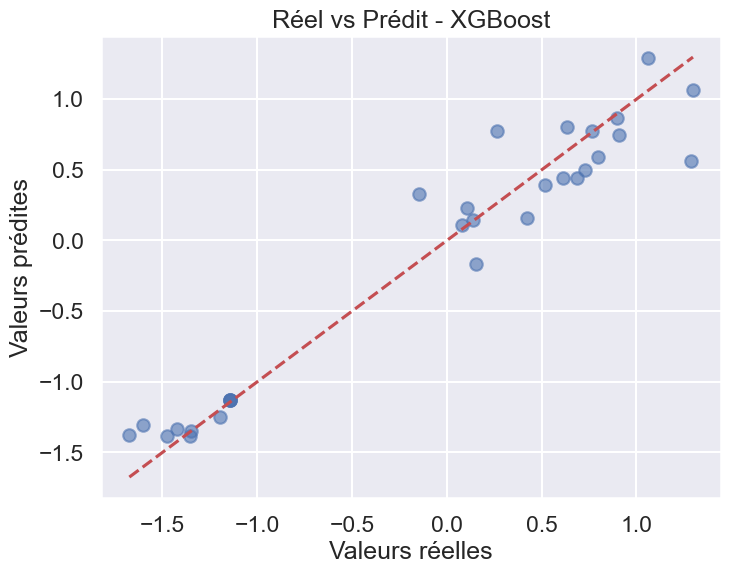

In [13]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialisation
model = XGBRegressor(
    max_depth=3,        # arbres moins profonds
    n_estimators=100,   # moins d'arbres
    learning_rate=0.1,
    subsample=0.8,      # échantillonnage aléatoire
    colsample_bytree=0.8,
    reg_alpha=0.1,      # régularisation L1
    reg_lambda=1.0      # régularisation L2
)

# Entraînement
model.fit(X_train, y_train)

# Prédiction sur le test set
y_pred = model.predict(X_test)



# Évaluation sur le test set
print("MAE (test):", mean_absolute_error(y_test, y_pred))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² (test):", r2_score(y_test, y_pred))
print(" ")

#évaluation sur le train set 
print("MAE (train):", mean_absolute_error(y_train, model.predict(X_train)))
print("RMSE (train):", np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
print("R² (train):", r2_score(y_train, model.predict(X_train)))


plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - XGBoost')
plt.show()



In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2, 3],             # max_depth : profondeur max des arbres — plus bas = moins d'overfitting
    'n_estimators': [100, 200, 300], # n_estimators : nombre d'arbres — plus = plus précis mais plus lent
    'learning_rate': [0.01, 0.05],   # learning_rate : taille du pas à chaque arbre — plus bas = plus robuste mais besoin de plus d'arbres
    'subsample': [0.6, 0.7],         # subsample : fraction des lignes utilisées par arbre — moins de 1 = moins d'overfitting
    'colsample_bytree': [0.6, 0.7],  # colsample_bytree : fraction des colonnes utilisées par arbre — moins de 1 = moins d'overfitting
    'reg_alpha': [0.5, 1.0, 2.0],    # reg_alpha : régularisation L1 — pousse les poids vers 0, sélection de features
    'reg_lambda': [2.0, 5.0],        # reg_lambda : régularisation L2 — pénalise les grands poids, lisse le modèle
    'min_child_weight': [5, 10, 15], # min_child_weight : poids minimum pour créer un nœud — plus élevé = splits plus conservateurs
}

grid_search = GridSearchCV(
    XGBRegressor(),
    param_grid,
    cv=10,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres:", grid_search.best_params_)
print("Meilleur R² (CV):", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nMAE (test):", mean_absolute_error(y_test, y_pred_best))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R² (test):", r2_score(y_test, y_pred_best))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))


Fitting 10 folds for each of 864 candidates, totalling 8640 fits
Meilleurs paramètres: {'colsample_bytree': 0.6, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 300, 'reg_alpha': 0.5, 'reg_lambda': 2.0, 'subsample': 0.7}
Meilleur R² (CV): 0.9126423942106197

MAE (test): 0.1752153465599625
RMSE (test): 0.22597135265136215
R² (test): 0.9475339057202927
R² (train): 0.9661958144689233


Le modèle XGBoost atteint un R² de 0.947 sur le jeu de test, ce qui constitue une performance solide. Cependant, avec seulement 148 échantillons, entraîner un modèle aussi complexe reste délicat, le manque de données augmente significativement le risque de surapprentissage, ce qui limite la capacité du modèle à généraliser sur de nouvelles observations.